<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  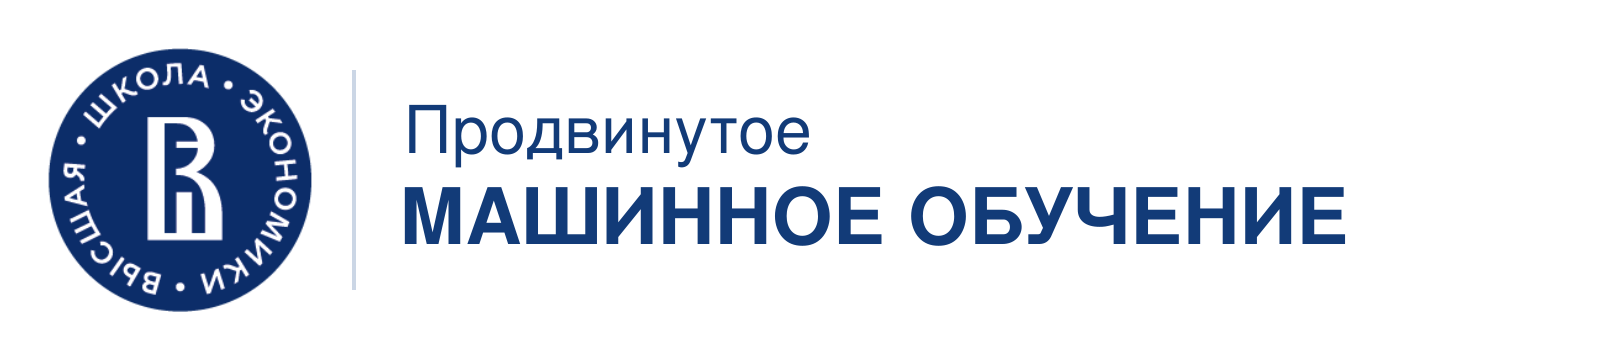

# Практика к лекции №2
## CART: решающие деревья
</div>


Бонусные задания по лекции №2 и **первой части** семинара о деревьях.


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from IPython.display import display

SEED = 42 # не меняйте сид, чтобы пройти ассерты
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 200,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8aa0b3",
    "axes.labelcolor": "#1b2a41",
    "xtick.color": "#4a5b6b",
    "ytick.color": "#4a5b6b",
    "text.color": "#1b2a41",
    "axes.facecolor": "#f7fafc",
    "figure.facecolor": "white",
    "grid.color": "#d7e0ea",
    "grid.linestyle": "--",
    "legend.frameon": False,
})
C_NAVY, C_GOLD, C_TEAL, C_ROSE = "#184f90", "#e7a33e", "#2a9d8f", "#c0392b"

### 1. Своя энтропия: насколько смешаны классы?

Напишите функцию `entropy(labels)`, которая получает **непустой одномерный
массив меток классов** и возвращает энтропию узла. Классов может быть больше двух.
Сначала найдите доли классов $p_k$, затем подставьте их в формулу:

$$\displaystyle H(R) = -\sum_{k=1}^{K} p_k\log_2 p_k,
\qquad p_k = \frac{n_k}{|R|}.$$

Здесь $n_k$ — число объектов класса $k$ в узле $R$. Чистый узел содержит
один класс и имеет нулевую энтропию. Слагаемые с $p_k=0$ считаем равными нулю;
если считать только встретившиеся классы, таких слагаемых вообще не будет.

**Что сделать:** реализуйте функцию, запустите две проверки и примените её
к узлам в следующей ячейке. Для сравнения расчёт Джини уже готов:

$$\displaystyle G(R) = 1 - \sum_{k=1}^{K} p_k^2.$$

Подсказка: частоты классов можно получить через `np.unique(labels, return_counts=True)`.


In [13]:
def entropy(labels):
    labels = np.asarray(labels)
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p)))


def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(1 - np.sum(probabilities ** 2))


# ассерты включатся, когда вы замените return None своей реализацией.
if entropy([1, 1, 1]) is None:
    print("Сначала реализуйте entropy(labels).")
else:
    assert np.isclose(entropy([1, 1, 1]), 0.0), "Чистый узел: H = 0."
    assert np.isclose(entropy([0, 0, 1, 1]), 1.0), "Два класса поровну: H = 1."
    print("Обе проверки пройдены.")


Обе проверки пройдены.


In [14]:
nodes = {
    "Один класс": [1, 1, 1, 1, 1, 1],
    "Два класса: 3 / 3": [0, 0, 0, 1, 1, 1],
    "Два класса: 1 / 5": [0, 1, 1, 1, 1, 1],
    "Три класса: 2 / 2 / 2": [0, 0, 1, 1, 2, 2],
}

if entropy(nodes["Один класс"]) is None:
    print("Таблица появится после реализации entropy. Сначала поработайте с кодом выше")
else:
    impurity_table = pd.DataFrame([
        {"Узел": name, "Энтропия": entropy(labels), "Джини": gini(labels)}
        for name, labels in nodes.items()
    ])
    display(impurity_table.round(3))


,Узел,Энтропия,Джини
0,Один класс,-0.000,0.000
1,Два класса: 3 / 3,1.000,0.500
2,Два класса: 1 / 5,0.650,0.278
3,Три класса: 2 / 2 / 2,1.585,0.667


**Объясните своими словами.**

1. Почему узел с пропорцией 3 / 3 имеет большую энтропию, чем узел 1 / 5?
   Что в этих двух случаях показывает Джини?
2. Может ли энтропия быть больше 1? Используйте строку с тремя классами.
   Значит ли большее численное значение энтропии по сравнению с Джини,
   что один критерий «лучше» другого?

**Ваш ответ:**
* В узле 3/3 оба класса равновероятны, поскольку исход максимально неопределённый для двух классов, $H=1$. В 1/5 почти всё одного класса, неопределённость меньше ($H\approx 0.65$). Джини ведёт себя так же, где 0.50 против $\approx 0.28$. Оба критерия штрафуют смешанность, просто разными формулами.
* Да, энтропия может быть больше 1, поскольку максимум $\log_2 K$. Для трёх равновероятных классов $H=\log_2 3\approx 1.585$. Джини при этом $\approx 0.667$. Разный масштаб не значит, что один критерий лучше, так как сравнивать 1.585 против 0.667 не имеет смысла. Это разные меры impurity, а качество разбиения смотрят по gain внутри одного критерия.

### 2. Какой порог выберет дерево?

Используем вашу энтропию для одного шага построения дерева. У нас 10 объектов
с одним признаком $x$. Порог $s$ отправляет объекты с $x\leq s$ в левый узел,
остальные — в правый. Хорошее разбиение уменьшает смешанность классов.

**Что сделать:** напишите `information_gain(labels, left_mask)` — уменьшение
энтропии после разбиения. `left_mask` — булев массив: `True` для левого узла.
В предлагаемых разбиениях оба дочерних узла непустые.

$$\displaystyle IG = H(R)
- \frac{|R_L|}{|R|}H(R_L)
- \frac{|R_R|}{|R|}H(R_R).$$

Чем больше $IG$, тем лучше разбиение по этому критерию. **Используйте свою
функцию `entropy` из задания 1.** Перебирать пороги с нуля не нужно:
код ниже проверит середины между соседними значениями признака.

Заодно посчитаем ещё один вариант: обычное среднее энтропий
двух узлов, **без учёта их размеров** (обсуждали с вами это в ходе занятия, теперь посмотрим на разницу на практике). Сравните, какие пороги получатся,
и проверьте правильный вариант через дерево глубины 1 из `sklearn`.


In [15]:
def information_gain(labels, left_mask):
    labels = np.asarray(labels)
    left_mask = np.asarray(left_mask, dtype=bool)
    left, right = labels[left_mask], labels[~left_mask]
    n = len(labels)
    return entropy(labels) - (len(left) / n) * entropy(left) - (len(right) / n) * entropy(right)


if entropy([0, 1]) is None:
    print("Сначала завершите задание 1.")
elif information_gain([0, 0, 1, 1], [True, True, False, False]) is None:
    print("Теперь реализуйте information_gain.")
else:
    assert np.isclose(
        information_gain([0, 0, 1, 1], [True, True, False, False]), 1.0
    ), "Если оба дочерних узла чистые, IG равен энтропии родителя."
    print("Проверка пройдена.")


Проверка пройдена.


In [16]:
x_split = np.arange(1, 11, dtype=float)
y_split = np.array([0, 0, 0, 0, 0, 0, 1, 1, 0, 1])
display(pd.DataFrame({"x": x_split, "Класс": y_split}).T)

thresholds = (x_split[:-1] + x_split[1:]) / 2
split_rows = []
if entropy(y_split) is None:
    print("Нужна функция entropy из задания 1.")
elif information_gain(y_split, x_split <= thresholds[0]) is None:
    print("Таблица появится после реализации information_gain.")
else:
    for threshold in thresholds:
        left_mask = x_split <= threshold
        # здесь считаем и вариант без весов (чтобы дальше сравнить)
        gain_without_weights = entropy(y_split) - (
            entropy(y_split[left_mask]) + entropy(y_split[~left_mask])
        ) / 2
        split_rows.append({
            "Порог": threshold,
            "Слева": int(left_mask.sum()),
            "Справа": int((~left_mask).sum()),
            "IG с весами": information_gain(y_split, left_mask),
            "Без весов": gain_without_weights,
        })

split_results = pd.DataFrame(split_rows)
if not split_results.empty:
    display(split_results.round(3))


,0,1,2,3,4,5,6,7,8,9
x,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
Класс,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0


,Порог,Слева,Справа,IG с весами,Без весов
0,1.5,1,9,0.055,0.422
1,2.5,2,8,0.118,0.404
2,3.5,3,7,0.192,0.389
3,4.5,4,6,0.281,0.381
4,5.5,5,5,0.396,0.396
5,6.5,6,4,0.557,0.476
6,7.5,7,3,0.192,0.126
7,8.5,8,2,0.032,-0.024
8,9.5,9,1,0.194,0.499


Лучший порог по вашей функции: 6.5
Порог без учёта размеров узлов: 9.5
Порог дерева sklearn: 6.5


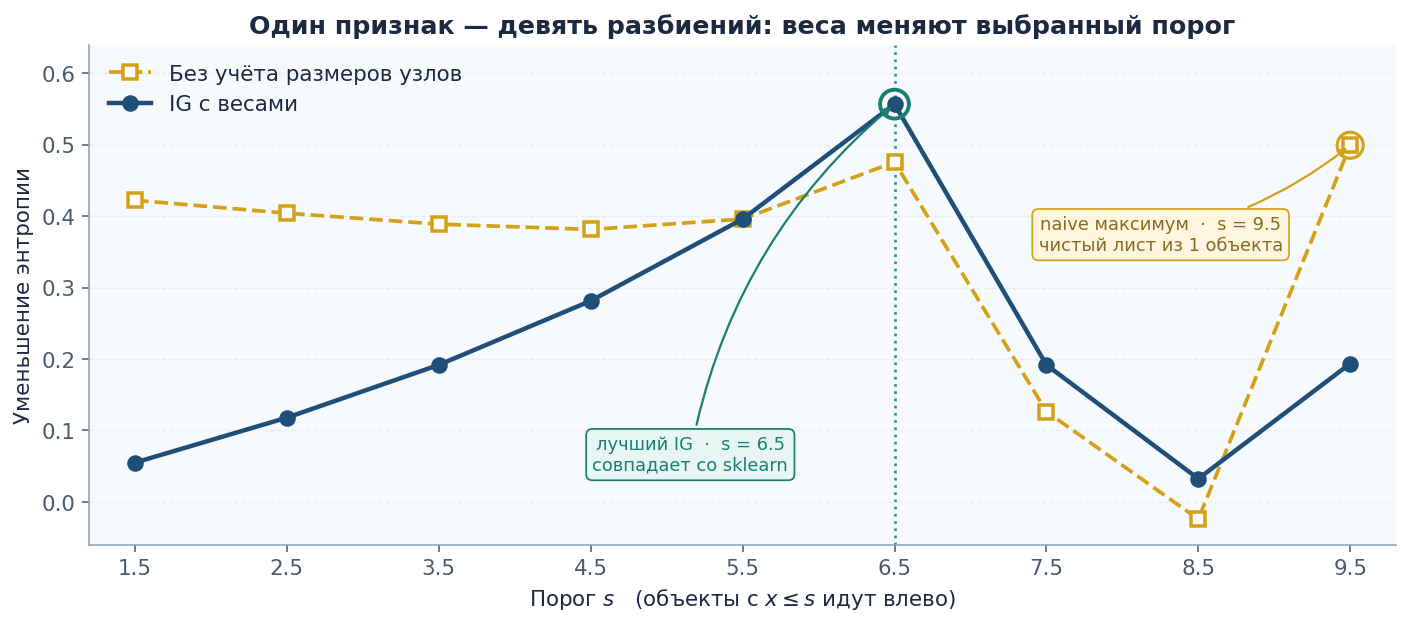

In [20]:
if split_results.empty:
    print("Сначала получите таблицу разбиений.")
else:
    best = split_results.loc[split_results["IG с весами"].idxmax()]
    naive = split_results.loc[split_results["Без весов"].idxmax()]
    stump = DecisionTreeClassifier(
        criterion="entropy", max_depth=1, random_state=SEED
    ).fit(x_split.reshape(-1, 1), y_split)
    sk_thr = float(stump.tree_.threshold[0])

    print(f"Лучший порог по вашей функции: {best['Порог']:.1f}")
    print(f"Порог без учёта размеров узлов: {naive['Порог']:.1f}")
    print(f"Порог дерева sklearn: {sk_thr:.1f}")

    C_NAVY, C_GOLD, C_TEAL = "#1f4e79", "#d4a017", "#1a7f72"

    fig, ax = plt.subplots(figsize=(10.2, 4.6))
    ax.plot(
        split_results["Порог"], split_results["Без весов"],
        ls="--", marker="s", color=C_GOLD, lw=1.9, ms=7.5,
        markerfacecolor="white", markeredgewidth=1.8,
        label="Без учёта размеров узлов", zorder=2,
    )
    ax.plot(
        split_results["Порог"], split_results["IG с весами"],
        ls="-", marker="o", color=C_NAVY, lw=2.3, ms=7.5,
        label="IG с весами", zorder=3,
    )
    ax.axvline(best["Порог"], color=C_TEAL, ls=":", lw=1.4, alpha=0.85, zorder=1)
    ax.scatter([best["Порог"]], [best["IG с весами"]],
               s=220, facecolors="none", edgecolors=C_TEAL, lw=2.0, zorder=5)
    ax.scatter([naive["Порог"]], [naive["Без весов"]],
               s=180, facecolors="none", edgecolors=C_GOLD, lw=1.6, zorder=5)

    ax.annotate(
        "лучший IG  ·  s = 6.5\nсовпадает со sklearn",
        xy=(best["Порог"], best["IG с весами"]),
        xytext=(0.46, 0.18), textcoords="axes fraction",
        ha="center", va="center", fontsize=9.2, color=C_TEAL,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="#e8f6f3",
                  edgecolor=C_TEAL, linewidth=0.9),
        arrowprops=dict(arrowstyle="-|>", color=C_TEAL, lw=1.15,
                        connectionstyle="arc3,rad=-0.18"),
    )
    ax.annotate(
        "naive максимум  ·  s = 9.5\nчистый лист из 1 объекта",
        xy=(naive["Порог"], naive["Без весов"]),
        xytext=(0.82, 0.62), textcoords="axes fraction",
        ha="center", va="center", fontsize=9.2, color="#8a6a20",
        bbox=dict(boxstyle="round,pad=0.35", facecolor="#fff6e0",
                  edgecolor=C_GOLD, linewidth=0.9),
        arrowprops=dict(arrowstyle="-|>", color=C_GOLD, lw=1.15,
                        connectionstyle="arc3,rad=0.12"),
    )

    ax.set(
        xlim=(1.2, 9.8), ylim=(-0.06, 0.64), xticks=thresholds,
        xlabel=r"Порог $s$   (объекты с $x \leq s$ идут влево)",
        ylabel="Уменьшение энтропии",
        title="Один признак — девять разбиений: веса меняют выбранный порог",
    )
    ax.grid(axis="y", color="#e6edf2", lw=0.7)
    ax.legend(loc="upper left", frameon=False)
    fig.tight_layout()
    plt.show()

**Объясните результат.**

1. Совпал ли ваш лучший порог с порогом `sklearn`? Почему при усреднении
   энтропий важно учитывать число объектов в каждом дочернем узле?
   Приведите пример из полученной таблицы.
2. Если один дочерний узел стал чистым, обязательно ли это лучшее разбиение?
   Посмотрите на последний порог.
3. Мы нашли лучший первый шаг. Гарантирует ли такой жадный выбор лучшее
   дерево целиком, если разрешить ему расти дальше?

**Ваш ответ:**

* Да, совпал. Веса нужны, потому что большой чистый лист важнее крошечного. Пример: порог 9.5 даёт чистый правый узел из одного объекта, naive-gain высокий ($\approx 0.50$), а честный IG только $\approx 0.19$. Порог 6.5 отделяет 6 чистых нулей слева и смешанную четвёрку справа, когда IG максимальный $\approx 0.557$.
* Нет. Последний порог 9.5 делает правый узел чистым, но слева остаётся 9 объектов с энтропией $\approx 0.76$. Это хуже, чем отрезать всю чистую пачку нулей на 6.5.
* Нет. Лучший первый сплит не гарантирует лучшее дерево целиком. Позже может оказаться выгоднее чуть худший первый шаг, если после него лучше раскладываются следующие признаки./

### 3. На семинаре было два признака — попробуем больше

Теперь возьмём **3 информативных признака и добавим 5 шумовых**,
сгенерированных независимо от целевого класса. Сравним три набора:
первые 2 признака, все 3 информативных и все 8 вместе.
Разбиение на train и validation уже зафиксировано и одинаково во всех опытах.

**Что сделать:** обучите по два дерева на каждом наборе — всего **6 моделей**.
Параметры заданы ниже: дерево без ограничения глубины и дерево с
`max_depth=4, min_samples_leaf=5`. Для всех используйте `criterion="entropy"`
и `random_state=SEED`.

Заполните таблицу: accuracy на train и validation, число листьев.
График построится автоматически. Затем измените `max_depth` или
`min_samples_leaf` у ограниченного дерева и повторите эксперимент один раз.

Все модели обучаем **только на train**. Validation используем для сравнения
и выбора параметров; это уже не независимая итоговая оценка качества.


In [21]:
X_signal, y = make_classification(
    n_samples=600, n_features=3, n_informative=3, n_redundant=0,
    class_sep=1.0, flip_y=0.06, random_state=SEED,
)
X_signal = X_signal[:, [0, 2, 1]]
rng = np.random.default_rng(SEED)
X = np.column_stack([X_signal, rng.normal(size=(len(y), 5))])
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED,
)

feature_sets = {
    "2 признака": [0, 1],
    "3 информативных": [0, 1, 2],
    "Все 8": list(range(8)), # 3 информативных и 5 шумовых (все как по условию выше)
}
configurations = {
    "Без ограничений": {"max_depth": None, "min_samples_leaf": 1},
    "С ограничениями": {"max_depth": 4, "min_samples_leaf": 5},
}
print("Train:", X_train.shape, "| Validation:", X_valid.shape)


Train: (420, 8) | Validation: (180, 8)


In [24]:
rows = []
for feature_name, columns in feature_sets.items():
    for model_name, params in configurations.items():
        tree = DecisionTreeClassifier(
            criterion="entropy",
            random_state=SEED,
            **params,
        )
        tree.fit(X_train[:, columns], y_train)
        rows.append({
            "features": feature_name,
            "model": model_name,
            "train_acc": tree.score(X_train[:, columns], y_train),
            "valid_acc": tree.score(X_valid[:, columns], y_valid),
            "leaves": tree.get_n_leaves(),
        })

results = pd.DataFrame(
    rows, columns=["features", "model", "train_acc", "valid_acc", "leaves"]
)
if results.empty:
    print("Заполните цикл: должно получиться 6 строк.")
else:
    results["gap"] = results["train_acc"] - results["valid_acc"]
    display(results.round(3))


,features,model,train_acc,valid_acc,leaves,gap
0,2 признака,Без ограничений,1.000,0.700,100,0.300
1,2 признака,С ограничениями,0.762,0.728,10,0.034
2,3 информативных,Без ограничений,1.000,0.872,46,0.128
3,3 информативных,С ограничениями,0.936,0.867,10,0.069
4,Все 8,Без ограничений,1.000,0.844,39,0.156
5,Все 8,С ограничениями,0.926,0.867,9,0.060


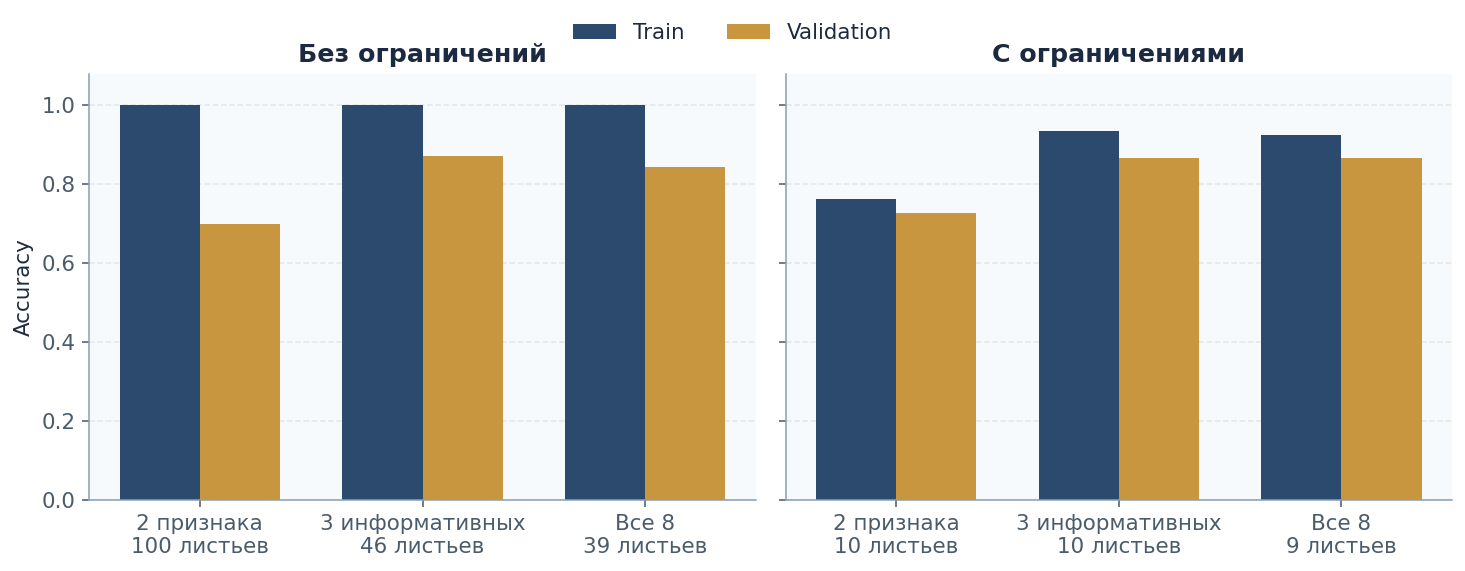

In [27]:
if results.empty:
    print("График появится после обучения моделей.")
else:
    C_NAVY, C_GOLD = "#2c4a6e", "#c8963e"
    names = list(feature_sets)
    positions = np.arange(len(names))
    width = 0.36

    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.0), sharey=True)
    for ax, model_name in zip(axes, configurations):
        part = (
            results[results["model"] == model_name]
            .set_index("features")
            .loc[names]
        )
        ax.bar(positions - width / 2, part["train_acc"], width, color=C_NAVY, label="Train")
        ax.bar(positions + width / 2, part["valid_acc"], width, color=C_GOLD, label="Validation")
        ax.set_xticks(positions)
        ax.set_xticklabels(
            [f"{name}\n{int(part.loc[name, 'leaves'])} листьев" for name in names]
        )
        ax.set_title(model_name)
        ax.set_ylim(0, 1.08)
        ax.yaxis.grid(True, color="#e2e8ee")
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_ylabel("Accuracy")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center", ncol=2,
        frameon=False, bbox_to_anchor=(0.5, 1.03),
    )
    fig.tight_layout()
    plt.show()

**Сделайте вывод.**

1. Что изменилось при добавлении третьего информативного признака?
   А после добавления шума? Должно ли увеличение числа признаков
   обязательно улучшать качество на новых данных?
2. Где заметно переобучение? Свяжите разницу train–validation с числом
   листьев. Что изменилось после вашей правки гиперпараметра?
3. Какую конфигурацию вы бы выбрали по validation и почему?
   На каких данных затем честно оценить качество выбранной модели?

**Ваш ответ:**

* Третий информативный признак поднимает validation примерно с 0.70 до 0.87. Шумовые пять признаков valid не улучшают, у дерева без ограничений он даже снижается до 0.84. Больше признаков не значит лучше на новых данных, если часть из них не несёт сигнал.
* Переобучение у деревьев без ограничений. train = 1.0 и много листьев (100 / 46 / 39). Ограничения оставляют около 10 листьев и сближают train с validation. Более жёсткая глубина ещё уменьшает число листьев и train, validation при этом почти не падает.
* По validation разумный выбор, поскольку три информативных признака и ограничения (valid 0.87). Честно измерить качество этой модели можно только на отложенном test, который не участвовал в обучении и в выборе конфигурации.